In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mma3001_project.reconstruction import (evaluate_methods, summarise_errors,
                                            bootstrap_rmse, METHODS)

clean = pd.read_csv("../data/processed/sensor869_clean.csv", index_col=0, parse_dates=True)
co2 = clean["co2_ppm"]
test_start = pd.Timestamp("2024-06-01", tz="Australia/Melbourne")
dev = co2[co2.index < test_start]
test = co2[co2.index >= test_start]
print("Development:", dev.index.min(), "to", dev.index.max(), len(dev), "slots")
print("Test:       ", test.index.min(), "to", test.index.max(), len(test), "slots")

Development: 2024-02-29 06:00:00+00:00 to 2024-05-31 13:50:00+00:00 13296 slots
Test:        2024-05-31 14:00:00+00:00 to 2024-06-13 17:40:00+00:00 1895 slots


In [2]:
lengths = [1, 3, 6, 18, 36, 72]          # 10 min, 30 min, 1 h, 3 h, 6 h, 12 h
dev_errors = evaluate_methods(dev, lengths, n_gaps=200, seed=1)
dev_table = summarise_errors(dev_errors)
dev_table["RMSE"].unstack("method").round(1)

method,cubic,linear,locf,newton,pchip
length,,,,,
1,12.5,10.4,12.3,11.5,10.6
3,15.9,10.6,13.8,13.5,11.1
6,21.3,12.5,17.2,17.3,12.8
18,47.4,15.5,24.0,35.0,16.1
36,94.4,21.4,34.6,68.4,22.3
72,175.8,32.1,46.7,123.0,33.6


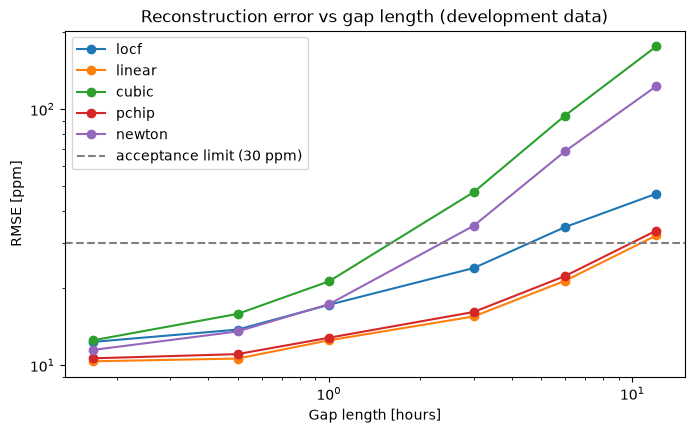

In [3]:
rmse = dev_table["RMSE"].unstack("method")
hours = rmse.index * 10 / 60
fig, ax = plt.subplots(figsize=(8, 4.5))
for m in METHODS:
    ax.plot(hours, rmse[m], "o-", label=m)
ax.axhline(30, color="grey", ls="--", label="acceptance limit (30 ppm)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Gap length [hours]"); ax.set_ylabel("RMSE [ppm]")
ax.set_title("Reconstruction error vs gap length (development data)")
ax.legend()
plt.show()

In [4]:
print(dev_table["bias"].unstack("method").round(1))
short = dev_errors[dev_errors["length"] == 1]
summarise_errors(short, by=("method", "occupied"))["RMSE"].unstack().round(1)

method  cubic  linear  locf  newton  pchip
length                                    
1        -0.8    -0.6  -0.7    -0.8   -0.6
3         1.1     0.7   0.4     1.0    0.7
6         0.2     0.6   0.5     0.3    0.7
18       -5.7    -0.3   0.8    -4.1   -0.8
36        5.9     1.0   1.4     2.9    1.1
72      -17.7     1.6  -0.3   -15.0    0.5


occupied,False,True
method,,
cubic,11.9,13.6
linear,10.0,11.1
locf,10.9,14.8
newton,11.0,12.3
pchip,10.2,11.5


In [5]:
test_errors = evaluate_methods(test, [1, 72], n_gaps=200, seed=2, methods=("locf", "linear"))
for length in [1, 72]:
    for m in ["locf", "linear"]:
        subset = test_errors[(test_errors["method"] == m) & (test_errors["length"] == length)]
        r, lo, hi = bootstrap_rmse(subset)
        print(f"{length*10:4d} min  {m:6s}  RMSE = {r:5.1f} ppm  (95% CI {lo:.1f} to {hi:.1f})")

  10 min  locf    RMSE =   9.7 ppm  (95% CI 8.8 to 10.7)
  10 min  linear  RMSE =   8.7 ppm  (95% CI 7.9 to 9.6)
 720 min  locf    RMSE =  20.0 ppm  (95% CI 18.7 to 21.3)
 720 min  linear  RMSE =  14.3 ppm  (95% CI 13.5 to 15.1)


In [6]:
os.makedirs("../results", exist_ok=True)
dev_table.to_csv("../results/validation_development.csv")
summarise_errors(test_errors).to_csv("../results/validation_test.csv")